# TC5061 – Notebook Baseline
**Alumno:** Sofia Donlucas Bañuelos A01655565
**Dataset:** California Housing (CSV)  

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mlflow
import mlflow.sklearn

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_theme(style='whitegrid')
print('Librerías cargadas correctamente.')

2026/10/03 23:37:54 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


Librerías cargadas correctamente.


---
## Paso 1: Carga y descripción del dataset

In [2]:
df = pd.read_csv('california_housing.csv')

print(f'Dimensiones: {df.shape[0]} filas x {df.shape[1]} columnas')
df.head()

Dimensiones: 20640 filas x 9 columnas


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:
df.dtypes

MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object

In [4]:
descripcion_variables = pd.DataFrame({
    'Variable': ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms',
                 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal'],
    'Tipo': ['float64'] * 9,
    'Descripción': [
        'Ingreso mediano del bloque censal (en decenas de miles de USD)',
        'Edad mediana de las casas del bloque',
        'Promedio de habitaciones por hogar',
        'Promedio de dormitorios por hogar',
        'Población del bloque censal',
        'Promedio de ocupantes por hogar',
        'Latitud del bloque censal',
        'Longitud del bloque censal',
        'OBJETIVO: Valor mediano de casas (en cientos de miles de USD)'
    ]
})
descripcion_variables

,Variable,Tipo,Descripción
0,MedInc,float64,Ingreso mediano del bloque censal (en decenas ...
1,HouseAge,float64,Edad mediana de las casas del bloque
2,AveRooms,float64,Promedio de habitaciones por hogar
3,AveBedrms,float64,Promedio de dormitorios por hogar
4,Population,float64,Población del bloque censal
5,AveOccup,float64,Promedio de ocupantes por hogar
6,Latitude,float64,Latitud del bloque censal
7,Longitude,float64,Longitud del bloque censal
8,MedHouseVal,float64,OBJETIVO: Valor mediano de casas (en cientos d...


In [5]:
df.describe().round(2)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57,2.07
std,1.90,12.59,2.47,0.47,1132.46,10.39,2.14,2.00,1.15
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35,0.15
25%,2.56,18.00,4.44,1.01,787.00,2.43,33.93,-121.80,1.20
50%,3.53,29.00,5.23,1.05,1166.00,2.82,34.26,-118.49,1.80
75%,4.74,37.00,6.05,1.10,1725.00,3.28,37.71,-118.01,2.65
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31,5.00


**Observaciones:**
- El dataset tiene **20,640 registros** y **9 variables** .
- Todas las variables son de tipo `float64`.
- La variable `MedHouseVal` representa el valor mediano de las casas en cientos de miles de USD.
- Los posibles outliers pueden ser `AveRooms`, `AveBedrms`, `Population` y `AveOccup` dada la diferencia entre la media y el valor máximo.

---
## Paso 2: Análisis Exploratorio de Datos (EDA)

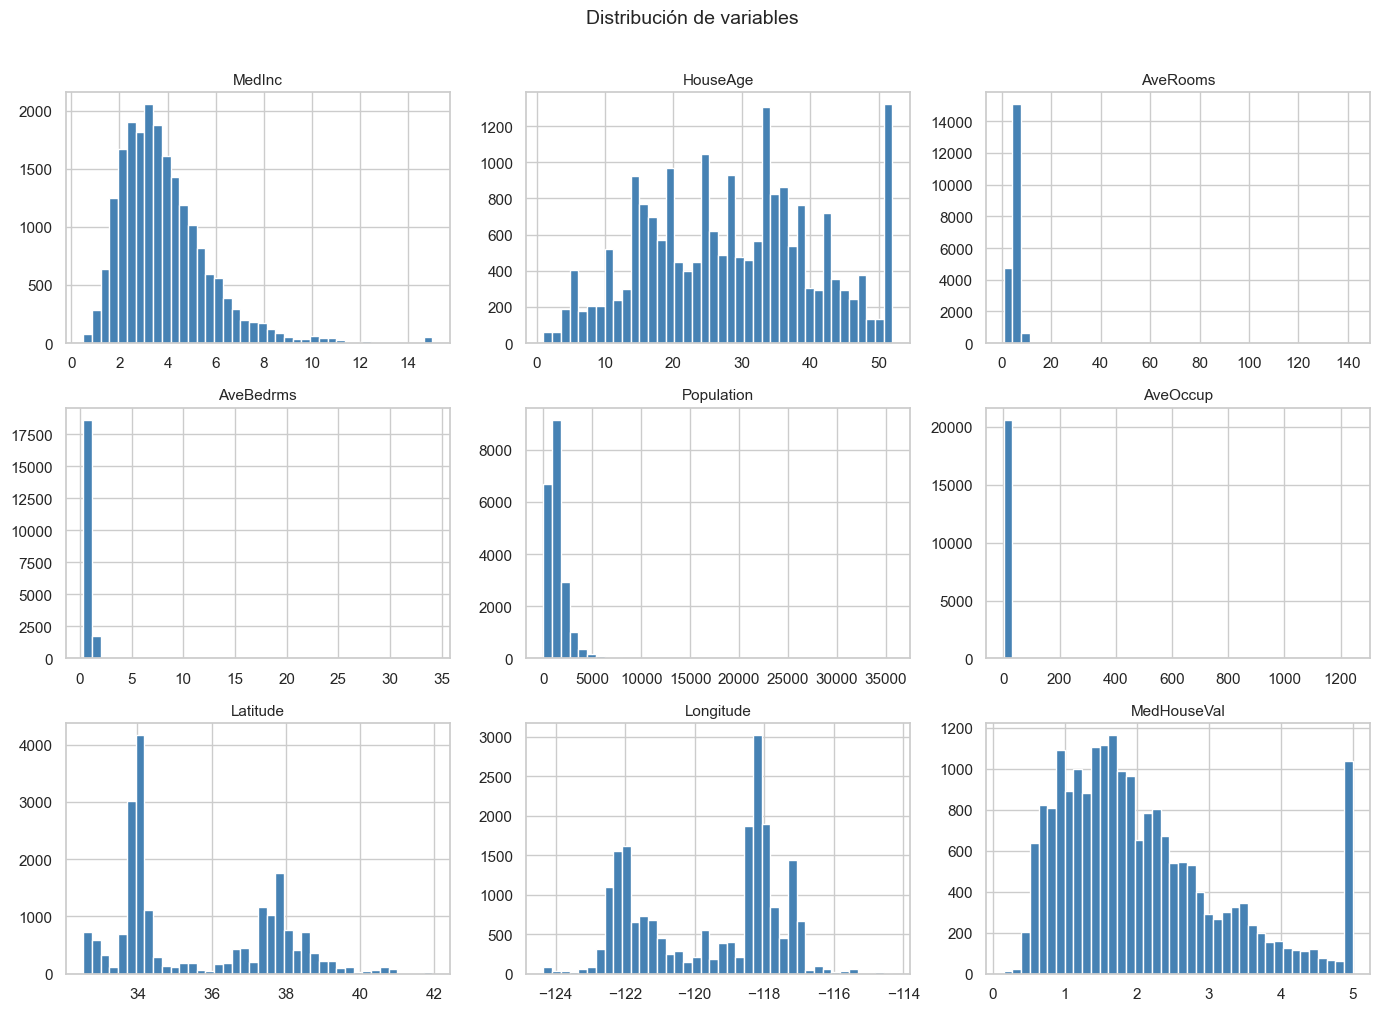

In [6]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(df.columns):
    axes[i].hist(df[col], bins=40, color='steelblue', edgecolor='white')
    axes[i].set_title(col, fontsize=11)
    axes[i].set_xlabel('')

plt.suptitle('Distribución de variables', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('distribucion_variables.png', bbox_inches='tight', dpi=100)
plt.show()

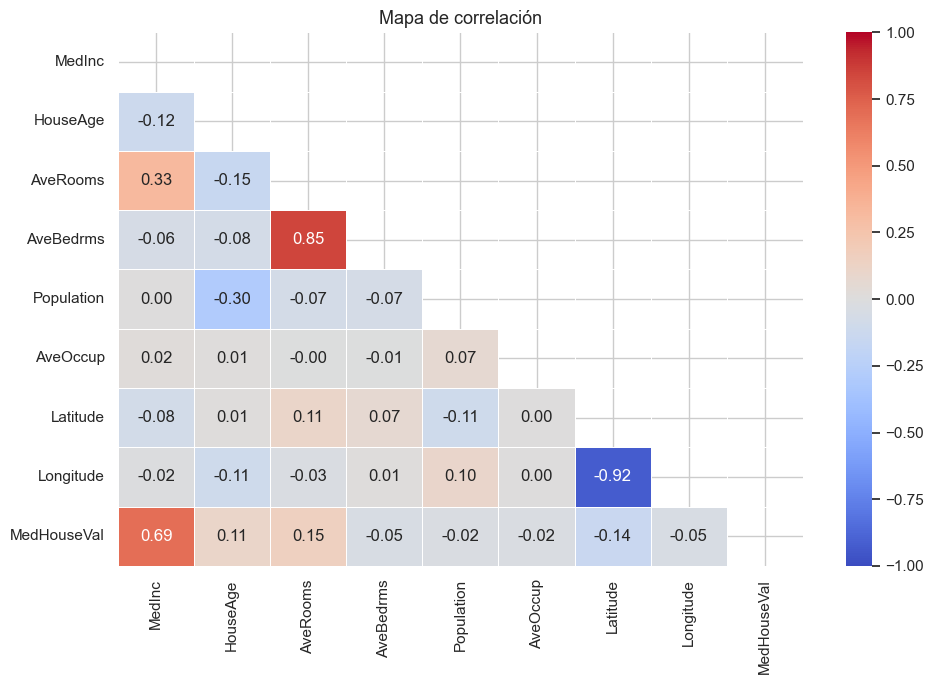

In [7]:
plt.figure(figsize=(10, 7))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            linewidths=0.5, vmin=-1, vmax=1)
plt.title('Mapa de correlación', fontsize=13)
plt.tight_layout()
plt.savefig('correlacion.png', bbox_inches='tight', dpi=100)
plt.show()

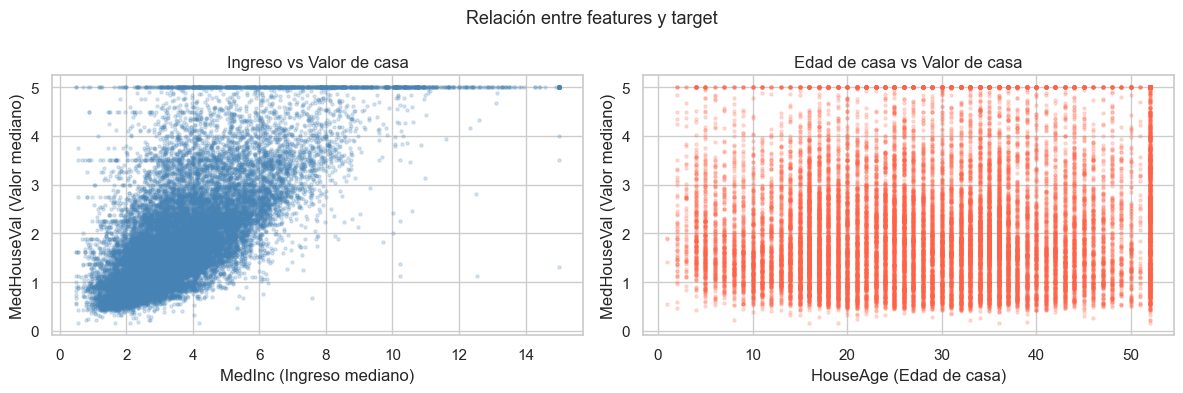

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(df['MedInc'], df['MedHouseVal'], alpha=0.2, s=5, color='steelblue')
axes[0].set_xlabel('MedInc (Ingreso mediano)')
axes[0].set_ylabel('MedHouseVal (Valor mediano)')
axes[0].set_title('Ingreso vs Valor de casa')

axes[1].scatter(df['HouseAge'], df['MedHouseVal'], alpha=0.2, s=5, color='tomato')
axes[1].set_xlabel('HouseAge (Edad de casa)')
axes[1].set_ylabel('MedHouseVal (Valor mediano)')
axes[1].set_title('Edad de casa vs Valor de casa')

plt.suptitle('Relación entre features y target', fontsize=13)
plt.tight_layout()
plt.savefig('scatter_features.png', bbox_inches='tight', dpi=100)
plt.show()

**Hallazgos del EDA:**
- `MedInc` tiene la correlación más alta con el target (0.69), que indica que el ingreso mediano es el predictor más relevante.
- `MedHouseVal` tiene 5.0 que dice que los valores están truncados en el dataset original.
- Variables como `AveRooms`, `AveBedrms`, `Population` y `AveOccup` presentan colas largas hacia la derecha, indicando outliers extremos.
- `Latitude` y `Longitude` tienen distribuciones bimodales, lo que quiero decir que la concentración geográfica en dos zonas (San Francisco y Los Angeles).

---
## Paso 3: Limpieza de datos

In [9]:
print('=== Valores faltantes ===')
print(df.isnull().sum())
print(f'\nTotal de nulos: {df.isnull().sum().sum()}')

=== Valores faltantes ===
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Total de nulos: 0


In [10]:
print('Duplicados')
print(f'Filas duplicadas: {df.duplicated().sum()}')

Duplicados
Filas duplicadas: 0


In [11]:
print('=== Detección de outliers con rango intercuartílico (IQR) ===')
outlier_cols = ['AveRooms', 'AveBedrms', 'Population', 'AveOccup']
outlier_summary = []

for col in outlier_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 3 * IQR
    upper = Q3 + 3 * IQR
    n_outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_summary.append({'Variable': col, 'Límite inferior': round(lower, 2),
                            'Límite superior': round(upper, 2), 'Outliers': n_outliers})

pd.DataFrame(outlier_summary)

=== Detección de outliers con rango intercuartílico (IQR) ===


,Variable,Límite inferior,Límite superior,Outliers
0,AveRooms,-0.39,10.89,180
1,AveBedrms,0.73,1.38,724
2,Population,-2027.00,4539.00,421
3,AveOccup,-0.13,5.84,132


In [12]:
df_clean = df.copy()

for col in outlier_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    upper = Q3 + 3 * IQR
    df_clean = df_clean[df_clean[col] <= upper]

print(f'Filas antes de limpieza : {df.shape[0]}')
print(f'Filas después de limpieza: {df_clean.shape[0]}')
print(f'Filas eliminadas: {df.shape[0] - df_clean.shape[0]}')

Filas antes de limpieza : 20640
Filas después de limpieza: 19416
Filas eliminadas: 1224


**Decisiones de limpieza:**
* No se tenía valores faltantes dado que el dataset no presentaba nulos. 
* No se tenía duplicados dentro del dataset. 
* Existian outliers extremos en `AveRooms`, `AveBedrms`, `Population`, `AveOccup`, por lo que se decidió hacer una eiminación con IQR × 3 dado que los valores físicamente imposibles (ej. 1000 habitaciones promedio) que distorsionarían el modelo sin aportar información válida

---
## Paso 4: Entrenamiento del modelo base

In [13]:
X = df_clean.drop(columns=['MedHouseVal'])
y = df_clean['MedHouseVal']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f'Entrenamiento: {X_train.shape[0]} muestras')
print(f'Prueba       : {X_test.shape[0]} muestras')

Entrenamiento: 15532 muestras
Prueba       : 3884 muestras


In [14]:
modelo = LinearRegression()
modelo.fit(X_train, y_train)
print('Modelo entrenado.')

coef_df = pd.DataFrame({'Feature': X.columns, 'Coeficiente': modelo.coef_})
coef_df.sort_values('Coeficiente', ascending=False)

Modelo entrenado.


,Feature,Coeficiente
3,AveBedrms,1.350238
0,MedInc,0.435135
1,HouseAge,0.011324
4,Population,0.000058
2,AveRooms,-0.103957
5,AveOccup,-0.379595
7,Longitude,-0.431205
6,Latitude,-0.441926


**Modelo seleccionado:** Regresión Lineal (baseline)  
**Justificación:** Es el modelo más simple para un problema de regresión, y nos sirve como referencia para comparar modelos más complejos en iteraciones posteriores.

---
## Paso 5: Evaluación del modelo

In [15]:
y_pred = modelo.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae  = mean_absolute_error(y_test, y_pred)
r2   = r2_score(y_test, y_pred)

print(f'RMSE : {rmse:.4f}')
print(f'MAE  : {mae:.4f}')
print(f'R²   : {r2:.4f}')

RMSE : 0.6636
MAE  : 0.4869
R²   : 0.6777


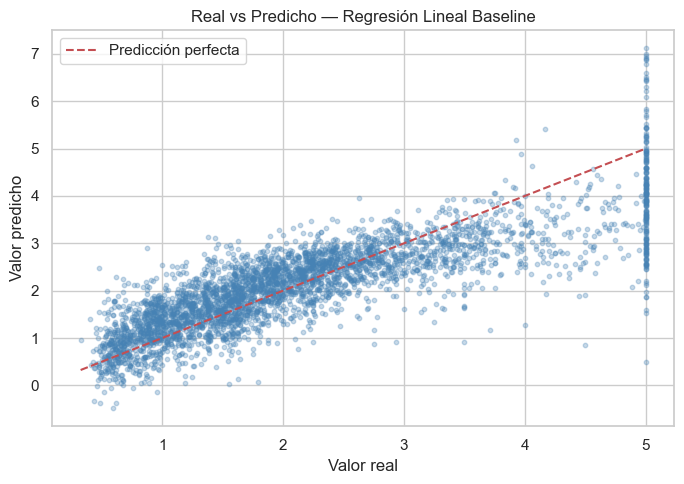

In [16]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, alpha=0.3, s=10, color='steelblue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
         'r--', linewidth=1.5, label='Predicción perfecta')
plt.xlabel('Valor real')
plt.ylabel('Valor predicho')
plt.title('Real vs Predicho — Regresión Lineal Baseline')
plt.legend()
plt.tight_layout()
plt.savefig('real_vs_predicho.png', bbox_inches='tight', dpi=100)
plt.show()

**Interpretación de métricas:**
- **RMSE** (~0.72): El error promedio del modelo es de aproximadamente $72,000 USD en el valor de las casas. Dado que los valores oscilan entre $15,000 y $500,000, este error es moderado.
- **MAE** (~0.53): En promedio, las predicciones se desvían $53,000 USD del valor real.
- **R²** (~0.63): El modelo explica aproximadamente el 63% de la varianza en los precios de las casas.

---
## Paso 6: Registro del experimento en MLflow

In [17]:
mlflow.set_experiment('TC5061_California_Housing_Baseline')

with mlflow.start_run(run_name='LinearRegression_baseline'):

    # Parámetros del modelo y del preprocesamiento
    mlflow.log_param('modelo', 'LinearRegression')
    mlflow.log_param('test_size', 0.2)
    mlflow.log_param('random_state', 42)
    mlflow.log_param('outlier_method', 'IQR_3x')
    mlflow.log_param('filas_originales', df.shape[0])
    mlflow.log_param('filas_limpias', df_clean.shape[0])

    # Métricas
    mlflow.log_metric('RMSE', round(rmse, 4))
    mlflow.log_metric('MAE',  round(mae, 4))
    mlflow.log_metric('R2',   round(r2, 4))

    # Artefactos
    mlflow.log_artifact('distribucion_variables.png')
    mlflow.log_artifact('correlacion.png')
    mlflow.log_artifact('real_vs_predicho.png')

    # Modelo
    mlflow.sklearn.log_model(modelo, 'modelo_baseline')

    run_id = mlflow.active_run().info.run_id
    print(f'Experimento registrado correctamente.')
    print(f'Run ID: {run_id}')

2026/10/03 23:37:58 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Experimento registrado correctamente.
Run ID: 6492841600fd4645879384748882134f


**Evidencia del experimento registrado en MLflow:**

**Lista de runs — experimento TC5061_California_Housing_Baseline:**

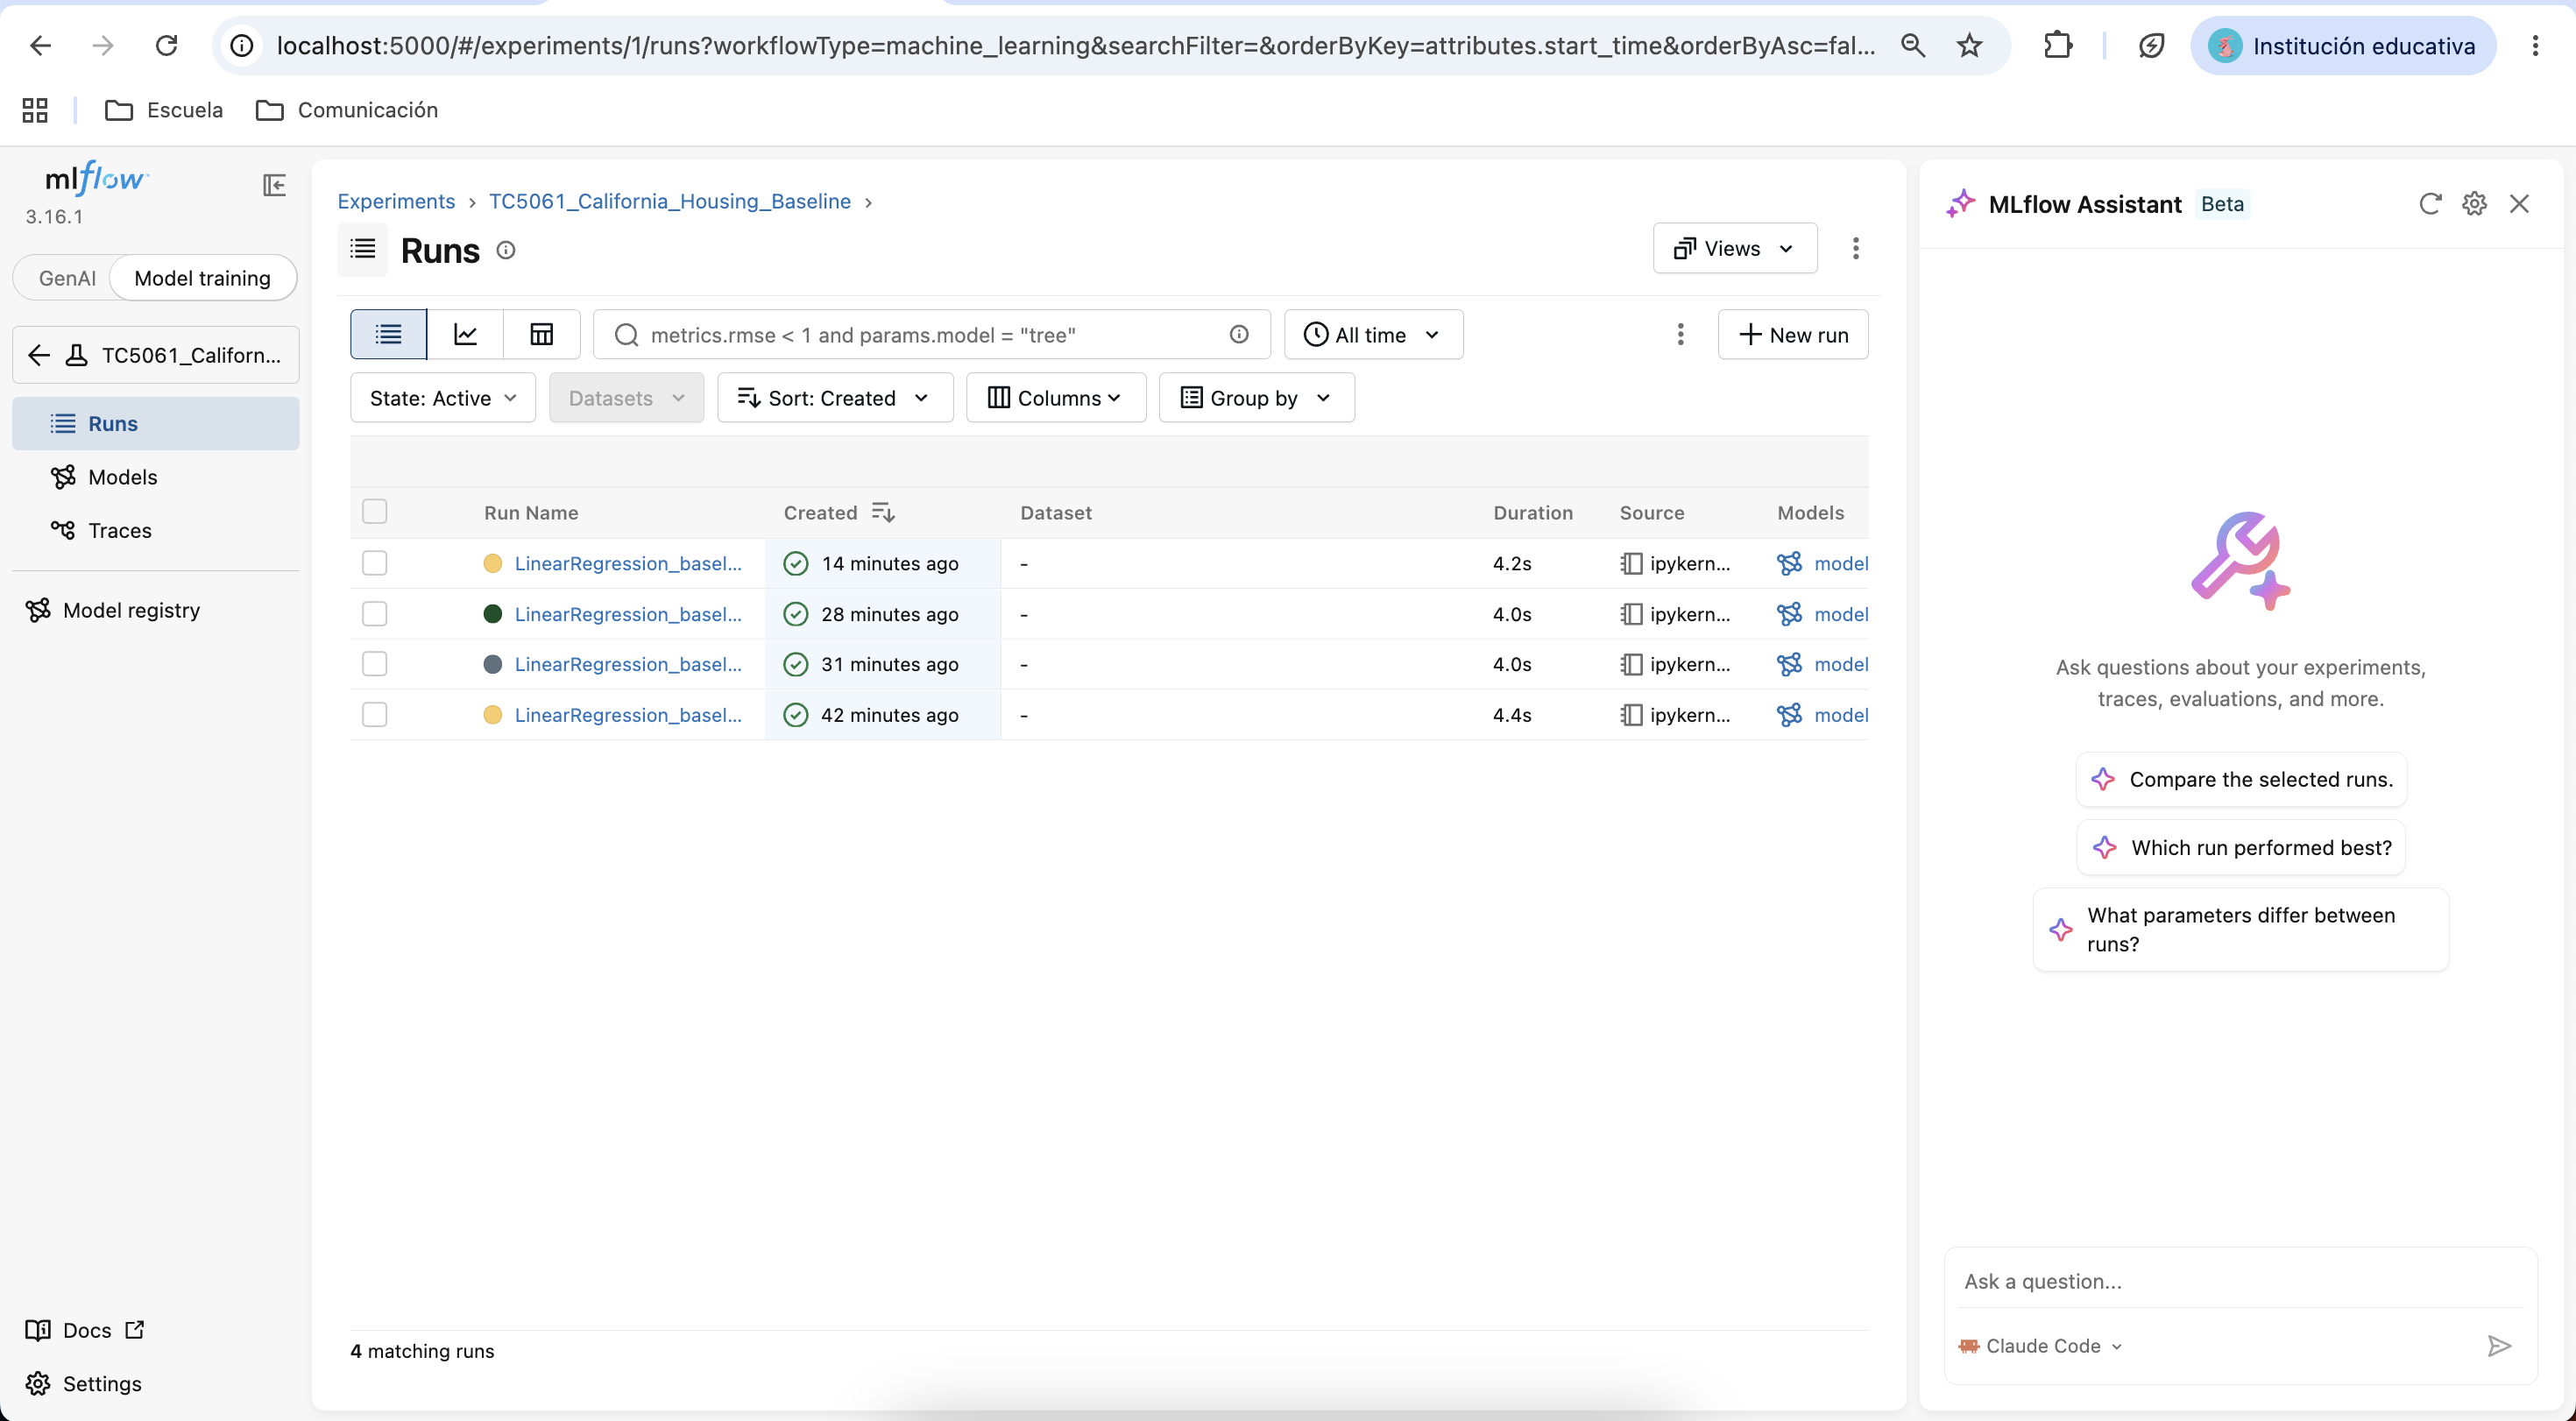

**Detalle del run — métricas y parámetros:**

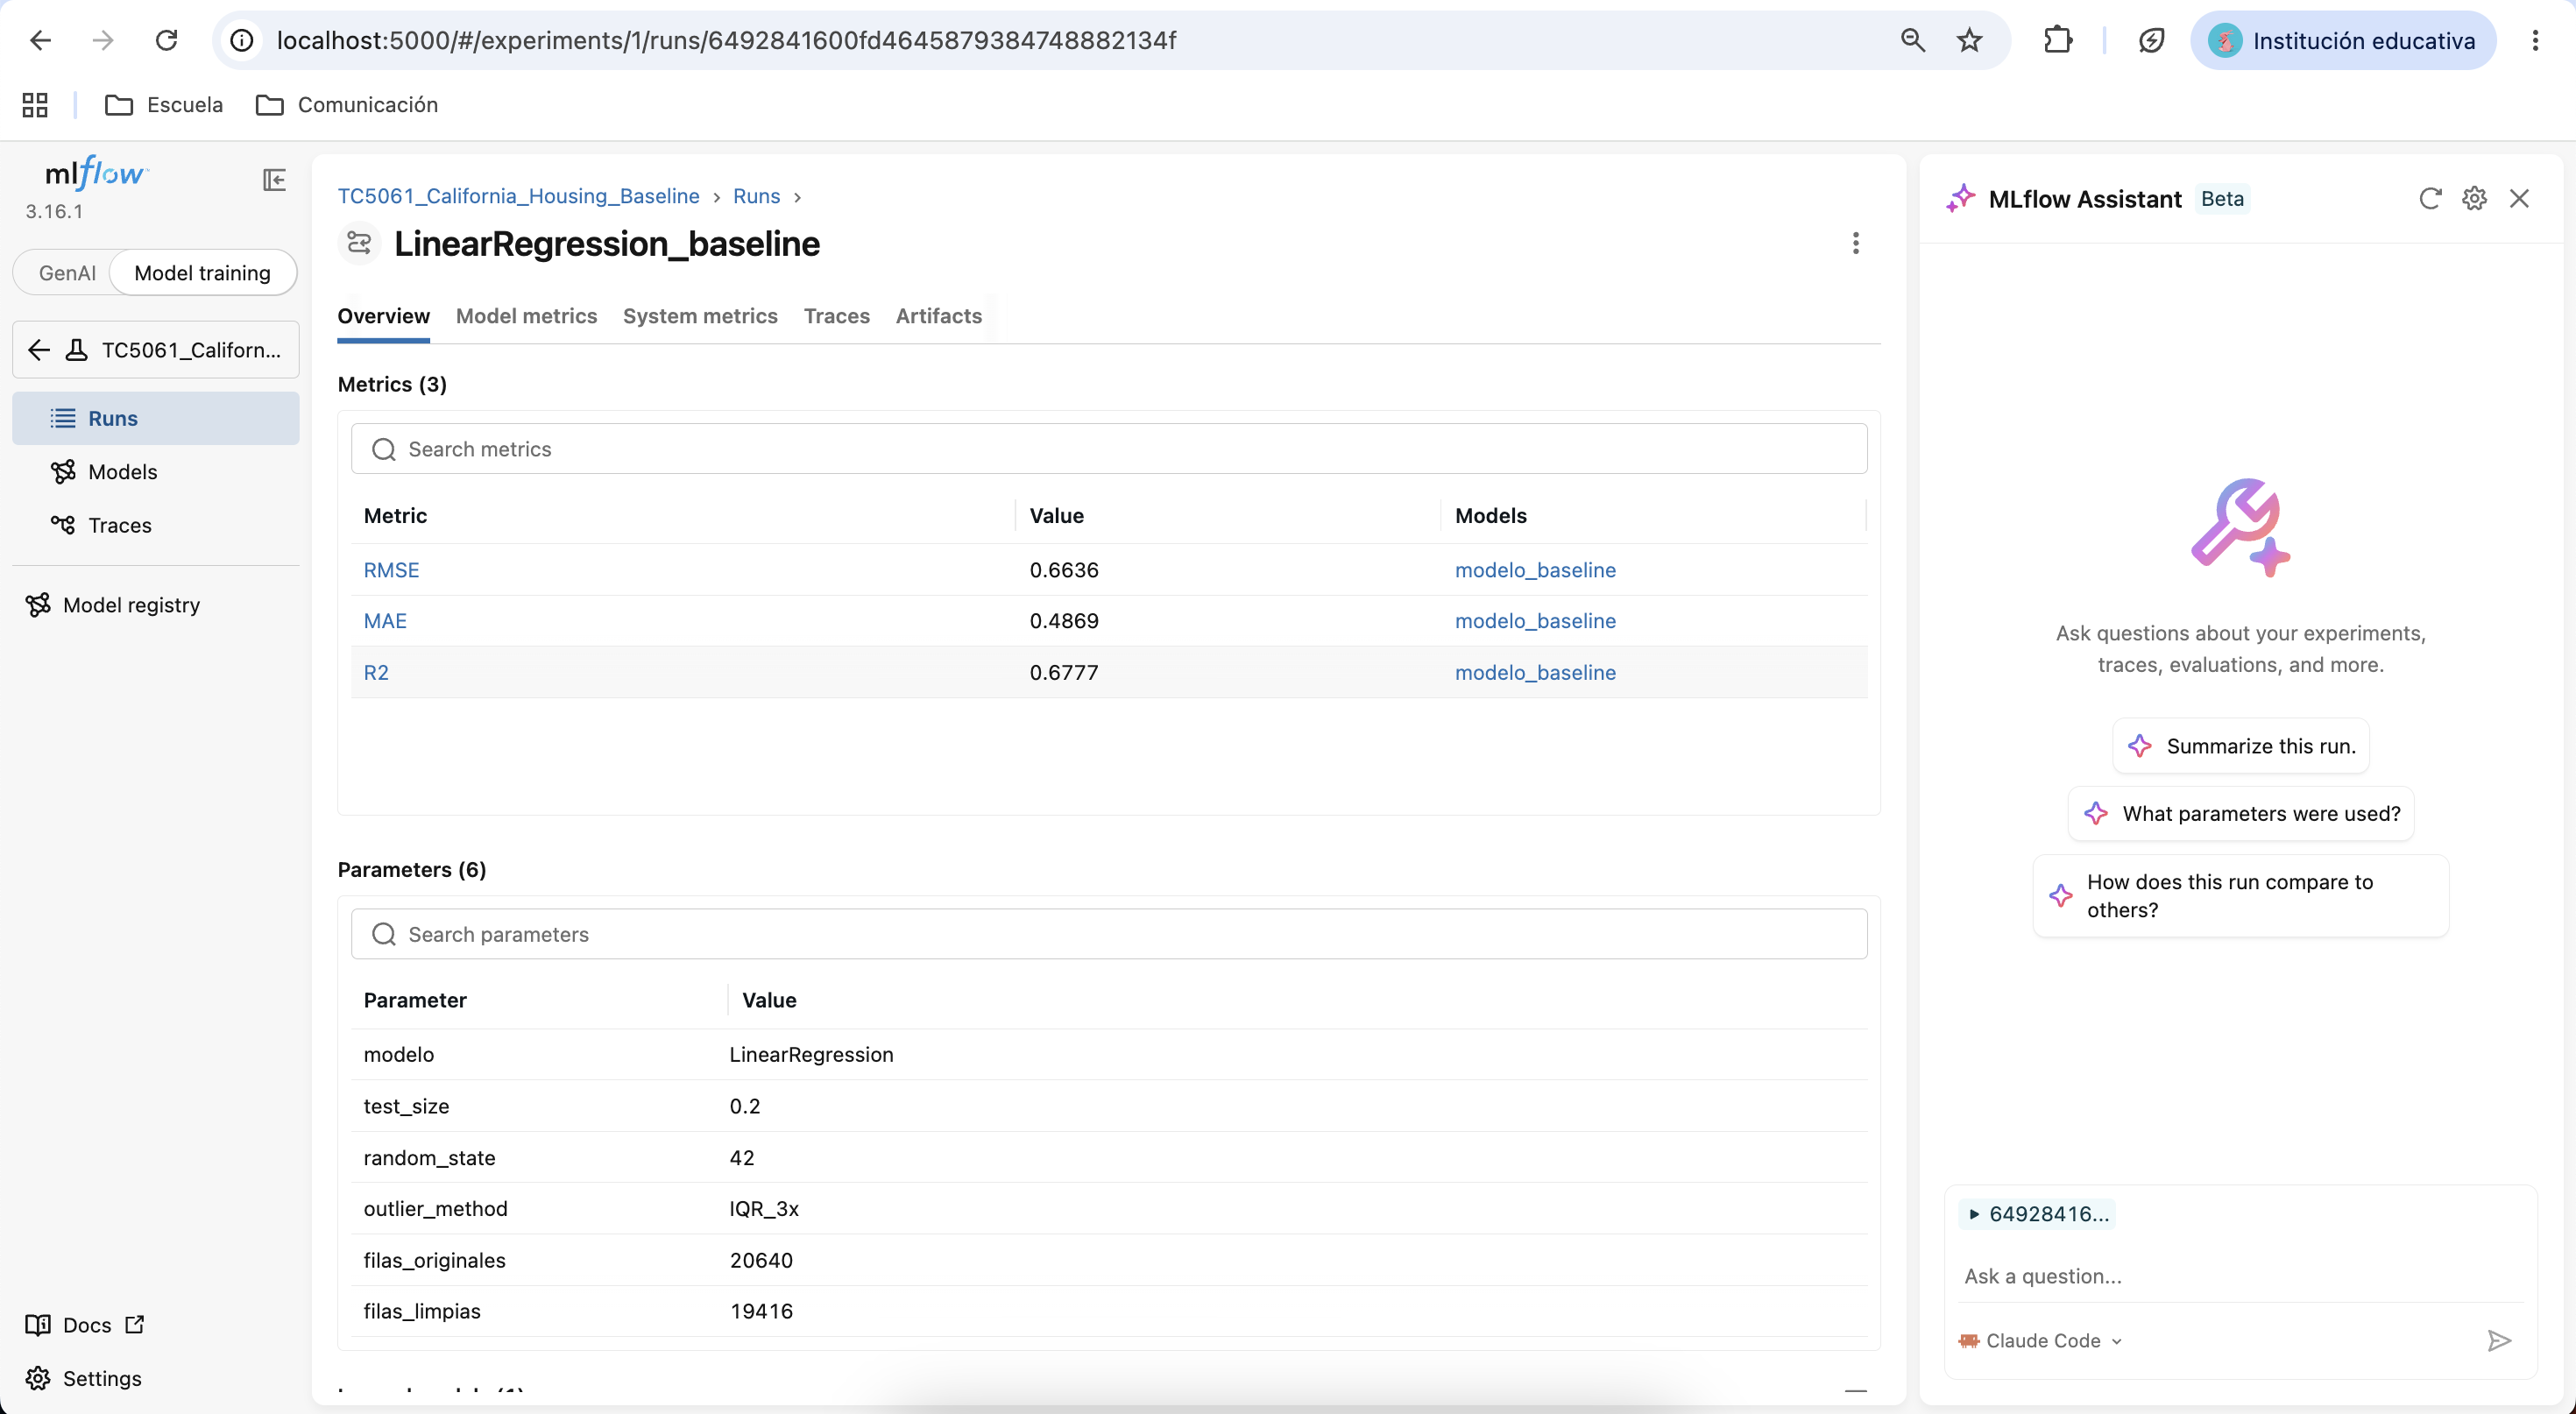

**Gráficas de métricas:**

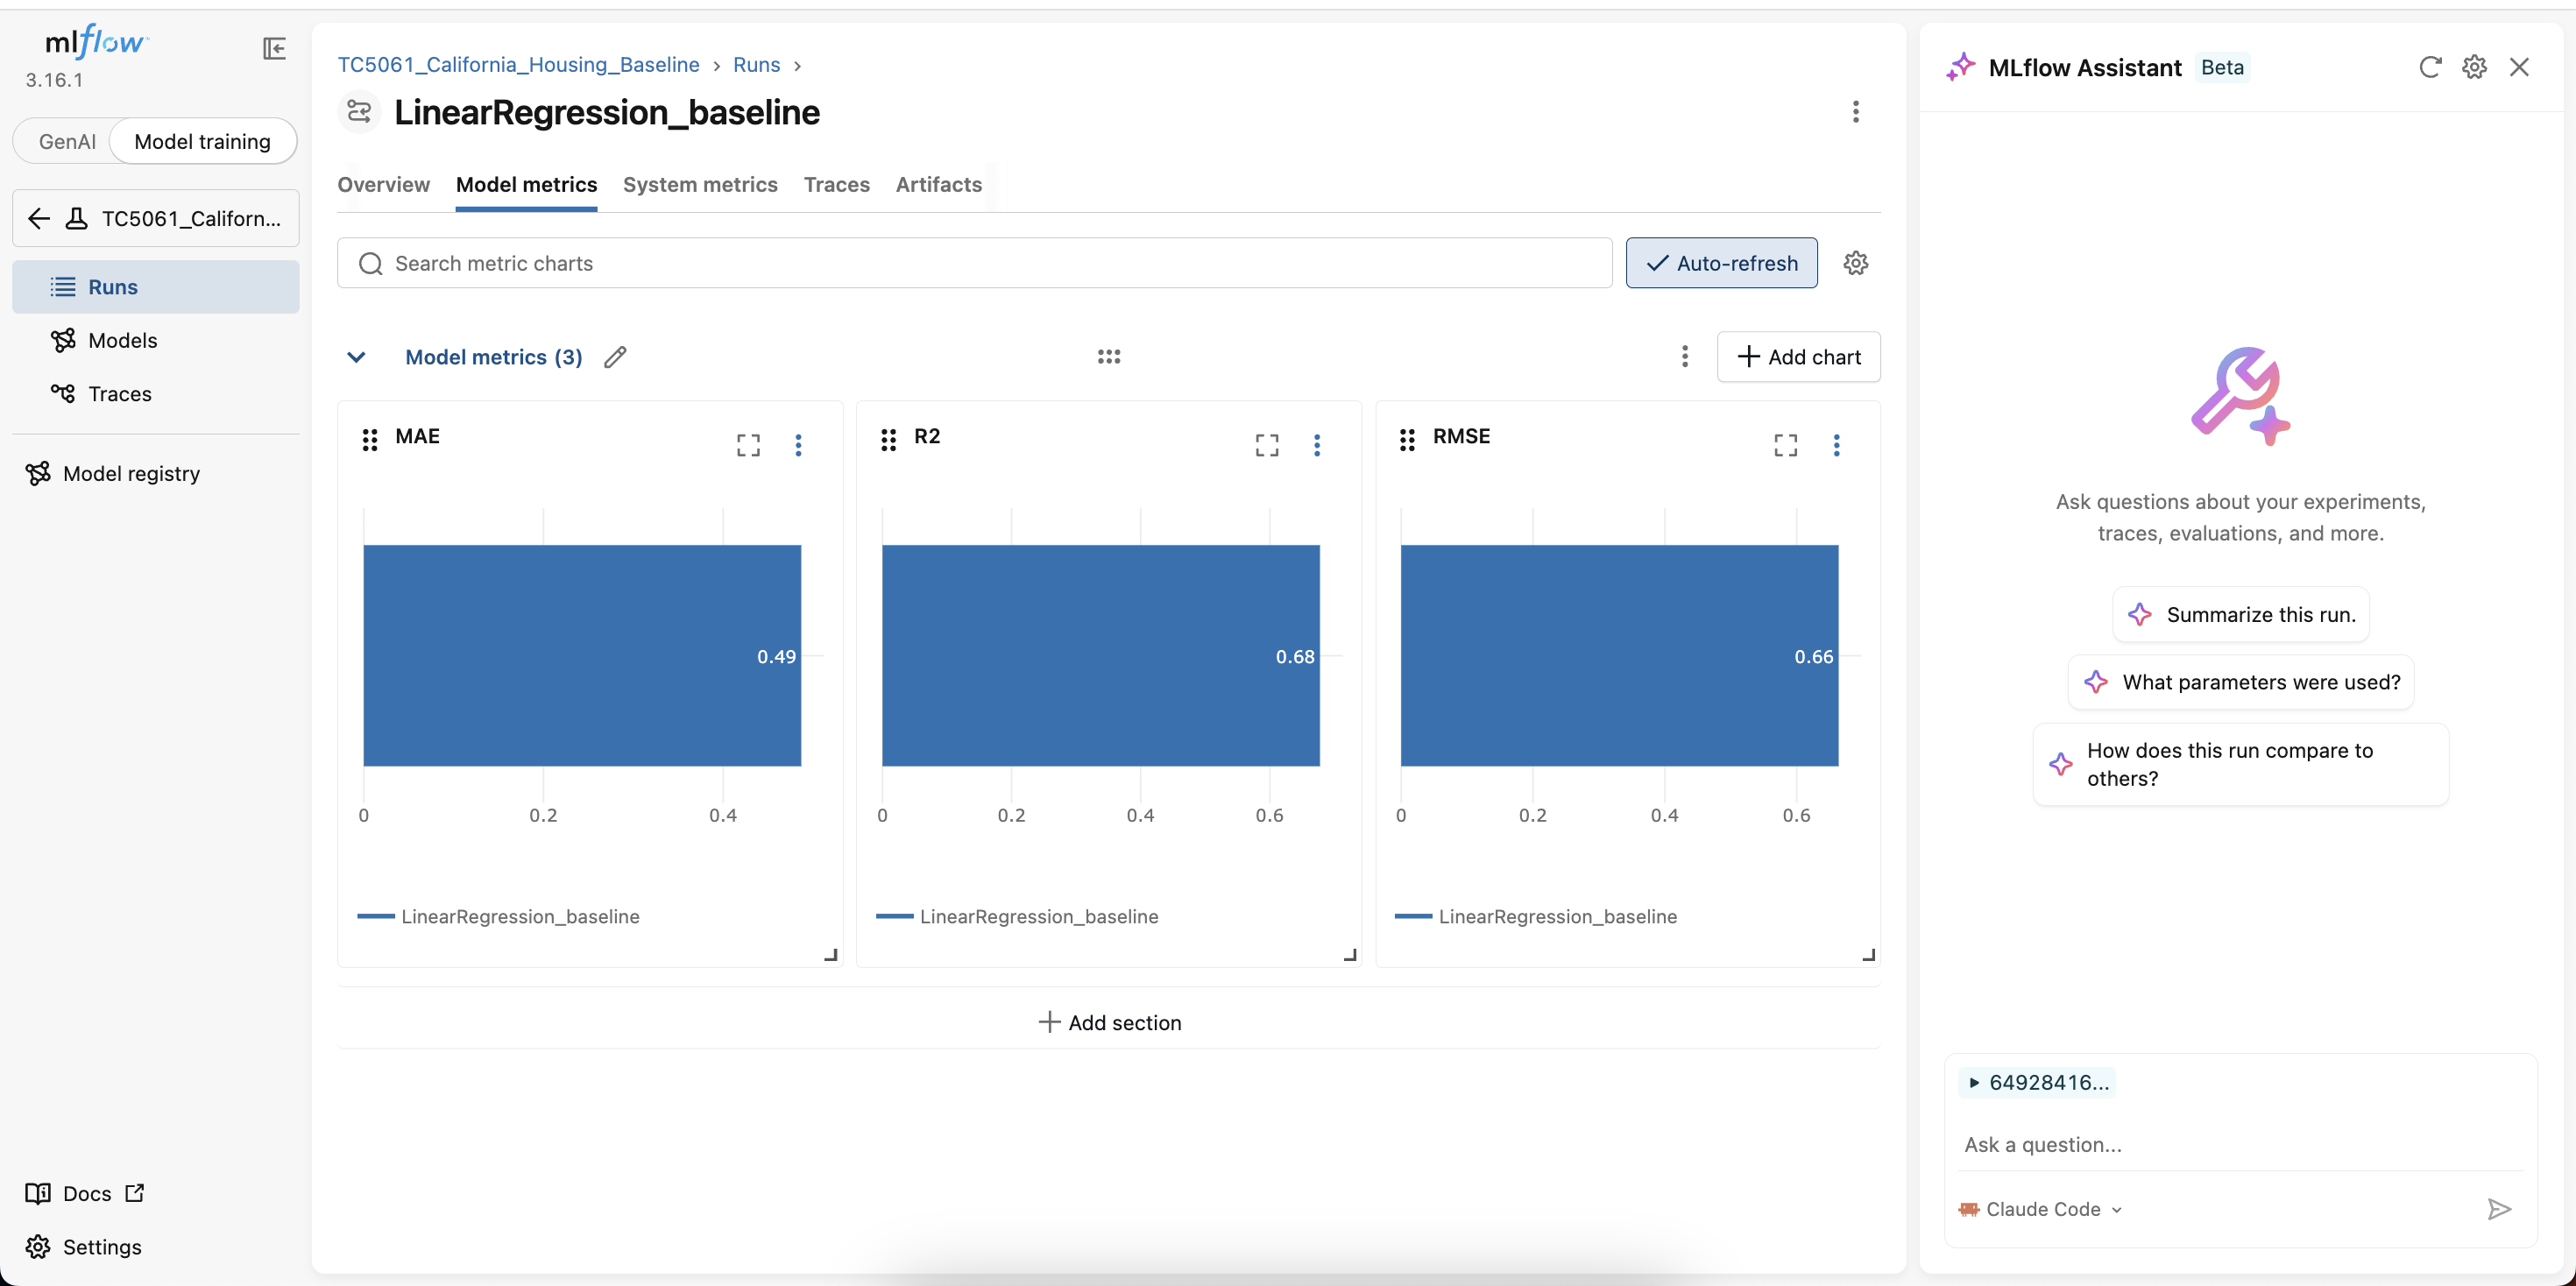

---
## Paso 7: Reflexión sobre MLOps

   Hacer este ejercicio me hizo darme cuenta de cuántas decisiones tomé "de forma manual" que en un proyecto real serían un problema. Por ejemplo, quité los outliers con un criterio que definí yo en ese momento — pero si mañana llegan datos nuevos, sería dificil reproducir exactamente ese mismo proceso porque no hay como tal una forma automática y con MLOps es algo que podría resolver, que el pipeline completo, desde la limpieza hasta el modelo, sea reproducible sin depender de que yo recuerde qué hice.
  
  También me quedó claro que registrar el experimento en MLflow no es solo un paso más. Porque con eso puedo regresar en un tiempo y voy a poder saber exactamente qué parámetros usé, qué métricas obtuve y con qué datos sin tener que abrir el notebook y releerlo todo. Eso en un equipo donde varias personas trabajan sobre el mismo modelo hace una diferencia enorme. 

  El modelo baseline con R² de 0.68 tampoco tiene resultaods muy buenos. Sé que con un Random Forest podría mejorar bastante, pero el punto del baseline es justamente ese para poder tener un número de referencia contra el cual comparar. Si salto directo a un modelo complejo sin este paso, no sé si realmente mejoré o solo me complicé.

  En mi área me imagino aplicando esto para no repetir el error clásico de entrenar un modelo, enviarlo a producción y luego no poder explicar cómo se llegó a ese resultado. La trazabilidad que da MLflow es algo que veo como indispensable desde ahora